# 1.0 — Exploratory data analysis: *Name that LLM*

Goal: predict which of 18 LLMs wrote each `text`. This notebook looks at

1. dataset shape, class balance and prompt coverage
2. length and stylometric features per model
3. words that are distinctive for each model
4. how similar models' answers to the **same prompt** are (which models will be confused)
5. the local test set

Figures are saved to `reports/figures/`.

In [1]:
import re
import warnings

from loguru import logger
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

from name_that_llm.config import FIGURES_DIR, RAW_DATA_DIR

logger.remove()
warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 200)
pd.set_option("display.width", 200)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
FIGURES_DIR.mkdir(parents=True, exist_ok=True)


def save(fig, name):
    fig.savefig(FIGURES_DIR / f"eda_{name}.png", bbox_inches="tight")

2026-11-03 22:19:06.451 | INFO     | name_that_llm.config:<module>:11 - PROJ_ROOT path is: C:\Users\Work\Desktop\New folder\name-that-llm


## 1. Load data

In [2]:
train = pd.read_csv(RAW_DATA_DIR / "train.csv")
test = pd.read_csv(RAW_DATA_DIR / "test.csv")
sub = pd.read_parquet(RAW_DATA_DIR / "sample_submission.parquet")

for name, df in [("train", train), ("test", test), ("sample_submission", sub)]:
    print(f"{name:18s} {df.shape}  columns={list(df.columns)}  nulls={int(df.isna().sum().sum())}")
print("duplicate texts in train:", train.text.duplicated().sum())
print("test texts also in train:", test.text.isin(train.text).sum())
train.head()

train              (2699, 4)  columns=['id', 'prompt_id', 'text', 'model']  nulls=0
test               (3, 2)  columns=['id', 'text']  nulls=0
sample_submission  (3, 2)  columns=['id', 'model']  nulls=0
duplicate texts in train: 0
test texts also in train: 0


,id,prompt_id,text,model
0,0018b3765972,p081,"When a language dies, a particular astronomy dims: not only names for stars, but whole grammars of attention that taught speakers how to read the night. Some tongues map the sky by kinship, bindin...",qwen3.8-max
1,0041ac86ee93,p073,"Data science communities matter because they accelerate learning through shared knowledge, code, and real-world problem-solving that no individual could develop alone. They connect beginners with ...",claude-sonnet-5
2,005a19083eae,p120,"In the final twilight of time, the last embers of ancient suns falter into silent rust, leaving behind a boundless sea of absolute frost. Galaxies have unspooled into phantom dust, their brilliant...",gemini-3.6-flash
3,009319596f10,p073,"Data science communities matter because they turn a fast-moving, technically demanding field into a shared practice rather than a solitary race to keep up. Through meetups, forums, open-source pro...",gpt-5.6-terra
4,00d3e8c92596,p097,"Deep inside each ear, three tiny loops of bone cradle a whisper of fluid, and every time you turn your head, that liquid sways like a tide. Nothing announces it—no sound, no shimmer—yet these micr...",glm-5.3-flash


## 2. Class balance and prompt coverage

Each model is also tagged with its **family** (claude / gpt / gemini / glm / qwen / kimi).

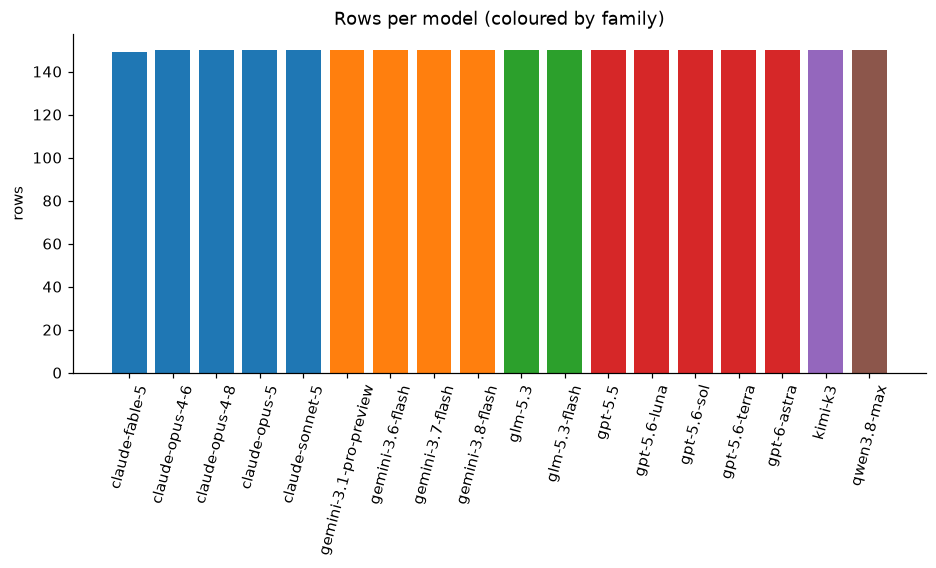

        models  rows
family              
claude       5   749
gemini       4   600
glm          2   300
gpt          5   750
kimi         1   150
qwen         1   150


In [3]:
train["family"] = train.model.str.extract(r"^([a-z]+)", expand=False)
MODEL_ORDER = sorted(train.model.unique(), key=lambda m: (train.loc[train.model == m, "family"].iloc[0], m))
FAMILIES = sorted(train.family.unique())
FAM_COLOR = dict(zip(FAMILIES, plt.cm.tab10.colors))

counts = train.model.value_counts().reindex(MODEL_ORDER)
fig, ax = plt.subplots(figsize=(10, 4))
model_family = train.drop_duplicates("model").set_index("model").family
ax.bar(counts.index, counts.values, color=[FAM_COLOR[model_family[m]] for m in counts.index])
ax.set_ylabel("rows"); ax.set_title("Rows per model (coloured by family)")
ax.tick_params(axis="x", rotation=75)
save(fig, "class_balance"); plt.show()

print(train.groupby("family").model.agg(["nunique", "size"]).rename(columns={"nunique": "models", "size": "rows"}))

In [4]:
per_prompt = train.groupby("prompt_id").model.nunique()
print("models answering each prompt:", per_prompt.value_counts().to_dict())
missing = set(MODEL_ORDER) - set(train.loc[train.prompt_id.isin(per_prompt[per_prompt < 18].index), "model"])
print("prompts with a gap:", list(per_prompt[per_prompt < 18].index), "-> missing model(s):", missing)

models answering each prompt: {18: 149, 17: 1}
prompts with a gap: ['p002'] -> missing model(s): {'claude-fable-5'}


Every prompt was answered by (almost) every model, so **topic carries no information about the model**.
A random train/validation split would put the same prompt on both sides; validation must be grouped by `prompt_id`.

## 3. Length

Words, sentences and paragraphs per text, by model.

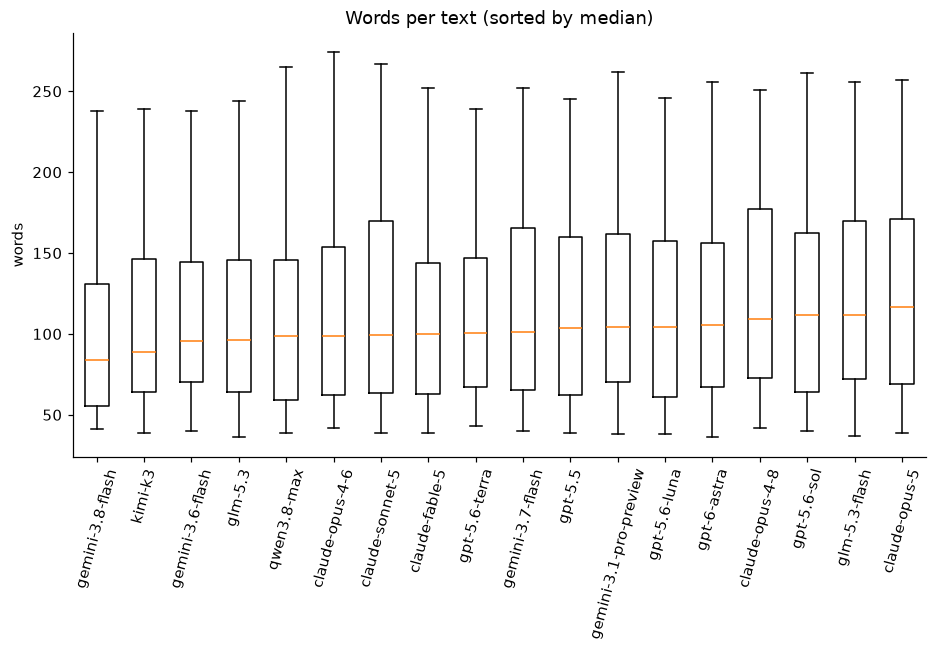

,words,sentences,paragraphs,words_per_sentence
model,,,,
gemini-3.8-flash,84.0,4.0,1.0,21.5
kimi-k3,89.0,4.0,1.0,23.5
gemini-3.6-flash,95.5,4.0,1.0,22.4
glm-5.3,96.0,5.0,1.0,21.2
qwen3.8-max,98.5,4.0,1.0,21.8
claude-opus-4-6,98.5,4.0,1.0,26.5
claude-sonnet-5,99.5,4.0,1.0,25.0
claude-fable-5,100.0,5.0,1.0,22.8
gpt-5.6-terra,100.5,4.0,1.0,24.3


In [5]:
def sentences(t):
    return max(1, len([s for s in re.split(r"(?<=[.!?])\s+", t.strip()) if s]))

train["chars"] = train.text.str.len()
train["words"] = train.text.str.split().str.len()
train["sentences"] = train.text.map(sentences)
train["paragraphs"] = train.text.str.count(r"\n\s*\n") + 1
train["words_per_sentence"] = train.words / train.sentences

order_len = train.groupby("model").words.median().sort_values().index
fig, ax = plt.subplots(figsize=(10, 5))
ax.boxplot([train.loc[train.model == m, "words"] for m in order_len], tick_labels=order_len, showfliers=False)
ax.set_ylabel("words"); ax.set_title("Words per text (sorted by median)")
ax.tick_params(axis="x", rotation=75)
save(fig, "length_by_model"); plt.show()

train.groupby("model")[["words", "sentences", "paragraphs", "words_per_sentence"]].median().round(1).sort_values("words")

Length differs a little between models, but the distributions overlap heavily.

Is length driven by the **prompt** more than the model? Compare the spread of length across prompts with the spread across models:

In [6]:
print("std of per-prompt mean words:", round(train.groupby("prompt_id").words.mean().std(), 1))
print("std of per-model  mean words:", round(train.groupby("model").words.mean().std(), 1))

# length relative to the prompt's average removes the prompt effect
train["words_rel"] = train.words / train.groupby("prompt_id").words.transform("mean")
train.groupby("model").words_rel.mean().sort_values().round(3).to_frame("words / prompt mean")

std of per-prompt mean words: 13.1
std of per-model  mean words: 6.0


,words / prompt mean
model,
gemini-3.8-flash,0.882
kimi-k3,0.936
qwen3.8-max,0.949
glm-5.3,0.966
gpt-5.5,0.968
claude-fable-5,0.975
gemini-3.6-flash,0.980
gpt-5.6-terra,0.985
claude-opus-4-6,0.999


## 4. Stylometric features

Punctuation and formatting habits are often more model-specific than vocabulary.
Rates are per 100 words (or a share of texts, for the `has_*` columns).

In [7]:
per100 = lambda pat: train.text.str.count(pat) / train.words * 100

style = pd.DataFrame({
    "model": train.model,
    "em_dash": per100("\u2014"),
    "en_dash": per100("\u2013"),
    "hyphen_spaced": per100(r" - "),
    "semicolon": per100(";"),
    "colon": per100(":"),
    "comma": per100(","),
    "question": per100(r"\?"),
    "exclaim": per100("!"),
    "parens": per100(r"\("),
    "curly_quote": per100("[\u2018\u2019\u201c\u201d]"),
    "straight_quote": per100("['\"]"),
    "ellipsis": per100(r"\u2026|\.\.\."),
    "digits": per100(r"\d"),
    "has_markdown": train.text.str.contains(r"\*\*|^#|^\s*[-*] ", regex=True, flags=re.M).astype(float) * 100,
    "has_newline": train.text.str.contains("\n").astype(float) * 100,
    "avg_word_len": train.text.str.replace(r"[^\w\s]", "", regex=True).str.split().map(lambda w: np.mean([len(x) for x in w])),
    "type_token": train.text.str.lower().str.findall(r"[a-z']+").map(lambda w: len(set(w)) / max(1, len(w))),
    "words_per_sentence": train.words_per_sentence,
})
constant = [c for c in style.columns if c != "model" and style[c].nunique() <= 1]
print("dropped (identical for every text):", constant)
style = style.drop(columns=constant)
style_means = style.groupby("model").mean().reindex(MODEL_ORDER)
style_means.round(2)

dropped (identical for every text): ['hyphen_spaced', 'has_markdown', 'has_newline']


,em_dash,en_dash,semicolon,colon,comma,question,exclaim,parens,curly_quote,straight_quote,ellipsis,digits,avg_word_len,type_token,words_per_sentence
model,,,,,,,,,,,,,,,
claude-fable-5,1.39,0.00,0.35,0.68,9.33,0.04,0.00,0.04,0.00,1.19,0.0,0.68,5.40,0.81,24.13
claude-opus-4-6,1.14,0.00,0.12,0.38,7.82,0.03,0.00,0.00,0.00,1.17,0.0,0.61,5.66,0.82,27.24
claude-opus-4-8,0.87,0.00,0.19,0.51,9.63,0.04,0.00,0.01,0.00,1.04,0.0,0.43,5.47,0.80,23.89
claude-opus-5,1.24,0.01,0.59,0.80,8.45,0.05,0.02,0.01,0.00,1.23,0.0,0.64,5.09,0.78,23.83
claude-sonnet-5,1.25,0.00,0.24,0.60,9.81,0.01,0.01,0.00,0.00,1.76,0.0,0.45,5.70,0.82,26.21
gemini-3.1-pro-preview,0.00,0.00,0.16,0.16,7.57,0.05,0.01,0.00,0.05,0.15,0.0,0.20,5.50,0.80,20.26
gemini-3.6-flash,0.00,0.00,0.20,0.17,8.37,0.04,0.00,0.01,0.21,0.32,0.0,0.13,5.71,0.83,24.65
gemini-3.7-flash,0.01,0.00,0.20,0.17,8.26,0.03,0.00,0.01,0.36,0.18,0.0,0.21,5.94,0.84,23.87
gemini-3.8-flash,0.00,0.00,0.28,0.18,8.53,0.03,0.00,0.00,0.37,0.16,0.0,0.13,5.90,0.86,22.73


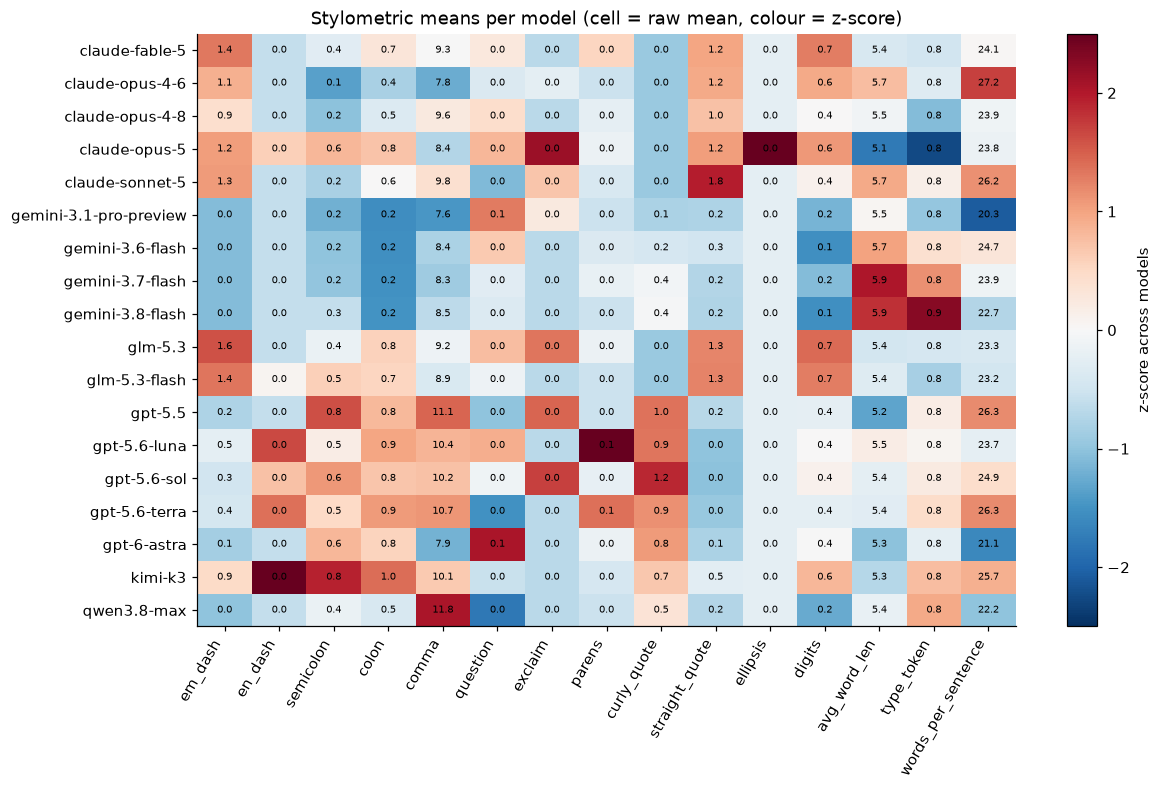

In [8]:
z = (style_means - style_means.mean()) / style_means.std().replace(0, 1)
fig, ax = plt.subplots(figsize=(12, 7))
im = ax.imshow(z.values, cmap="RdBu_r", vmin=-2.5, vmax=2.5, aspect="auto")
ax.set_xticks(range(z.shape[1]), z.columns, rotation=60, ha="right")
ax.set_yticks(range(z.shape[0]), z.index)
for (i, j), v in np.ndenumerate(style_means.values):
    ax.text(j, i, f"{v:.1f}", ha="center", va="center", fontsize=6.5, color="black")
fig.colorbar(im, ax=ax, label="z-score across models")
ax.set_title("Stylometric means per model (cell = raw mean, colour = z-score)")
save(fig, "stylometry_heatmap"); plt.show()

Which features separate models best? Ratio of between-model variance to within-model variance (a one-way ANOVA F-statistic):

In [9]:
from sklearn.feature_selection import f_classif

feats = style.drop(columns="model").fillna(0)
F, p = f_classif(feats, style.model)
pd.DataFrame({"F": F, "p": p}, index=feats.columns).sort_values("F", ascending=False).round(4)

,F,p
em_dash,89.6392,0.0000
straight_quote,49.4722,0.0000
curly_quote,36.9204,0.0000
avg_word_len,29.9555,0.0000
colon,27.4846,0.0000
comma,24.4527,0.0000
semicolon,19.3349,0.0000
type_token,6.5253,0.0000
words_per_sentence,4.9017,0.0000
digits,2.3144,0.0017


## 5. Distinctive words per model

Smoothed log-odds ratio of each word for one model vs. all others (unigrams + bigrams, min 10 documents).

In [10]:
cv = CountVectorizer(ngram_range=(1, 2), min_df=10, token_pattern=r"(?u)\b\w[\w']*\b", lowercase=True)
X = cv.fit_transform(train.text)
vocab = np.array(cv.get_feature_names_out())
print("vocabulary size:", len(vocab))

def log_odds(mask, alpha=1.0):
    a = np.asarray(X[mask].sum(0)).ravel() + alpha
    b = np.asarray(X[~mask].sum(0)).ravel() + alpha
    return np.log(a / a.sum()) - np.log(b / b.sum())

top = {}
for m in MODEL_ORDER:
    lo = log_odds((train.model == m).values)
    top[m] = ", ".join(vocab[np.argsort(-lo)[:12]])
pd.DataFrame.from_dict(top, orient="index", columns=["most over-used words vs. other models"])

vocabulary size: 7046


,most over-used words vs. other models
claude-fable-5,"insisting, c, living cell, has ever, on which, paradoxically, sliding, this ancient, ride, address, that what, n"
claude-opus-4-6,"traverse, somehow, into something, the architecture, boundary between, reply, their bodies, the observable, served, annihilate, architectures, the new"
claude-opus-4-8,"retreat, upon its, glimpse the, lifetime, this way, glimpse, famously, governs, notion, showing that, incompatible, you cannot"
claude-opus-5,"four hundred, which is, meant, and from, the sensation, a grain, of it, has learned, and it, a man, the rest, happen"
claude-sonnet-5,"life itself, infinitesimal, igniting, not just, isn't, lives in, long term, experts, folded into, perhaps a, to any, distinguish"
gemini-3.1-pro-preview,"strips away, acts as, actively, the ultimate, a sudden, the profound, acting as, harsh, to forge, the modern, relying, chorus of"
gemini-3.6-flash,"realm of, the delicate, severe, instant the, historical, alchemy, tranquil, from being, helpless, dynamic, expanse of, impulses"
gemini-3.7-flash,"an intricate, as these, intellect, parent, sheet of, demonstrating, tangible, crucible, impenetrable, explosive, known as, plumes of"
gemini-3.8-flash,"tempest, ethereal, majesty, ferocious, demonstrated, blind to, agonizing, intellect, permanently, undulating, across an, dormant"
glm-5.3,"way the, unborn, future where, four billion, count, in it, you and, rivers of, vent, hangs, really, shrink"


In [11]:
top_fam = {}
for f in FAMILIES:
    lo = log_odds((train.family == f).values)
    top_fam[f] = ", ".join(vocab[np.argsort(-lo)[:15]])
pd.DataFrame.from_dict(top_fam, orient="index", columns=["most over-used words vs. other families"])

,most over-used words vs. other families
claude,"isn't, four hundred, thousand miles, lying, doesn't, suggests that, and something, 5, that's, of it, the universe's, performs, universe's, degrees, mind's"
gemini,"suffocating, intellect, alchemy, precipice, vibrant, the precipice, precipice of, synthesize, expanse of, known as, but rather, the ultimate, crucible, tapestry, tapestry of"
glm,"overnight, writes, unborn, and when, wheel, riding, really, trusted, that they, mother's, whatever, perhaps a, you and, four billion, future where"
gpt,"helps, can become, another s, not mean, becomes less, than merely, a locked, that seem, helped, habits, harder to, entered, leaves a, roads, t"
kimi,"debt, patience of, a held, held breath, steering, it also, shining, the blood, keeps the, beloved, confess, a destination, loosens, address, anywhere"
qwen,"becoming a, delayed, pressing, fine, compress, breaths, treasures, pressure and, measurement, harvests, amplitudes, to trust, lift, starving, a luminous"


## 6. Which models write alike?

For every prompt, compare each pair of models' answers (TF-IDF cosine on word 1–2-grams and on character 3–5-grams),
then average over prompts. Comparing answers to the same prompt removes topic, so high similarity means similar *style*.
Pairs that stand out are the ones a classifier will confuse.

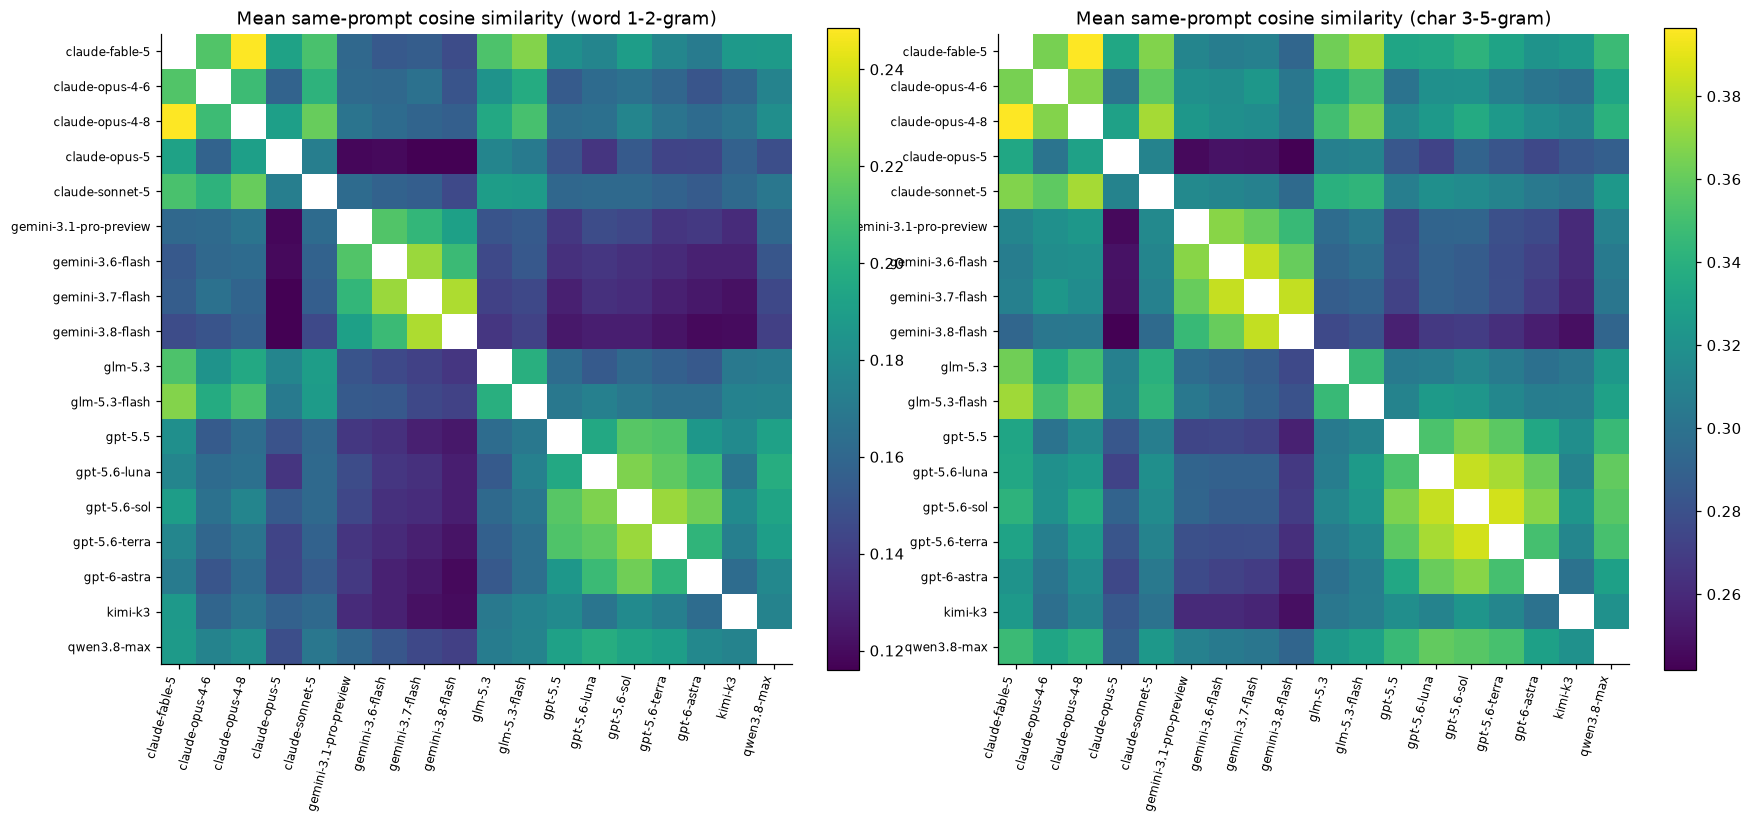

In [12]:
def pairwise_same_prompt(vec):
    V = vec.fit_transform(train.text)
    idx = {m: i for i, m in enumerate(MODEL_ORDER)}
    S, N = np.zeros((18, 18)), np.zeros((18, 18))
    for _, g in train.groupby("prompt_id"):
        sim = cosine_similarity(V[g.index])
        ids = g.model.map(idx).values
        S[np.ix_(ids, ids)] += sim
        N[np.ix_(ids, ids)] += 1
    return pd.DataFrame(S / N, index=MODEL_ORDER, columns=MODEL_ORDER)

sim_word = pairwise_same_prompt(TfidfVectorizer(ngram_range=(1, 2), sublinear_tf=True, min_df=2))
sim_char = pairwise_same_prompt(TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), sublinear_tf=True, min_df=3))

fig, axes = plt.subplots(1, 2, figsize=(18, 8))
for ax, (title, S) in zip(axes, [("word 1-2-gram", sim_word), ("char 3-5-gram", sim_char)]):
    M = S.values.copy(); np.fill_diagonal(M, np.nan)
    im = ax.imshow(M, cmap="viridis")
    ax.set_xticks(range(18), S.columns, rotation=75, ha="right", fontsize=8)
    ax.set_yticks(range(18), S.index, fontsize=8)
    ax.set_title(f"Mean same-prompt cosine similarity ({title})")
    fig.colorbar(im, ax=ax, fraction=0.046)
save(fig, "same_prompt_similarity"); plt.show()

In [13]:
def top_pairs(S, k=12):
    M = S.where(np.triu(np.ones(S.shape, bool), 1)).stack()
    return M.sort_values(ascending=False).head(k).round(3)

print("Most similar pairs (char n-grams):")
print(top_pairs(sim_char).to_string())
print("\nLeast similar pairs (char n-grams):")
print(sim_char.where(np.triu(np.ones(sim_char.shape, bool), 1)).stack().sort_values().head(6).round(3).to_string())

fam = model_family.reindex(MODEL_ORDER).to_numpy(dtype=object)
M = sim_char.values.copy(); np.fill_diagonal(M, np.nan)
same = fam[:, None] == fam[None, :]
print(f"\nmean similarity  within family: {np.nanmean(M[same]):.3f}   across families: {np.nanmean(M[~same]):.3f}")

Most similar pairs (char n-grams):
claude-fable-5          claude-opus-4-8     0.396
gpt-5.6-sol             gpt-5.6-terra       0.386
gpt-5.6-luna            gpt-5.6-sol         0.383
gemini-3.6-flash        gemini-3.7-flash    0.383
gemini-3.7-flash        gemini-3.8-flash    0.382
gpt-5.6-luna            gpt-5.6-terra       0.376
claude-opus-4-8         claude-sonnet-5     0.376
claude-fable-5          glm-5.3-flash       0.374
gpt-5.6-sol             gpt-6-astra         0.369
gemini-3.1-pro-preview  gemini-3.6-flash    0.369
claude-opus-4-6         claude-opus-4-8     0.368
claude-fable-5          claude-sonnet-5     0.367

Least similar pairs (char n-grams):
claude-opus-5     gemini-3.8-flash          0.242
                  gemini-3.1-pro-preview    0.246
gemini-3.8-flash  kimi-k3                   0.248
claude-opus-5     gemini-3.7-flash          0.249
                  gemini-3.6-flash          0.249
gemini-3.8-flash  gpt-6-astra               0.255

mean similarity  within fam

## 7. Example texts

One prompt, answered by every model — useful for eyeballing style.

In [14]:
example_prompt = train.groupby("prompt_id").words.mean().sort_values().index[len(per_prompt) // 4]  # a shortish prompt
ex = train[train.prompt_id == example_prompt].set_index("model").reindex(MODEL_ORDER).text
for m, t in ex.items():
    print(f"--- {m}\n{t}\n")

--- claude-fable-5
A billion years ago, two black holes spiraled into embrace, and spacetime shuddered—ripples cast outward like rings from a stone dropped in a cosmic pond. Through the long dark they traveled, stretching and squeezing the void, passing galaxies mid-birth, nebulae unfurling, stars kindling and dying. Undimmed by distance, patient as eternity, the waves whispered across the emptiness while Earth cooled, oceans rose, and life crawled from the sea. At last, faint as a tremor thinner than a proton's width, they brushed the mirrored arms of LIGO, and humanity, listening for the first time, heard the universe's ancient heartbeat.

--- claude-opus-4-6
Born in the cataclysmic embrace of two black holes spiraling into oblivion, gravitational waves departed their violent cradle and stretched across the cosmos like whispered tremors in the fabric of existence itself. They sailed through the silent architecture of spacetime, rippling past newborn galaxies, threading through nebula

## 8. Local test set

In [15]:
test["words"] = test.text.str.split().str.len()
print(test[["id", "words"]])
print("\nsample submission:")
print(sub)
print("\nsubmission ids match test ids:", set(sub.id) == set(test.id))

             id  words
0  00353fb1c541     48
1  005f5a9a6139    111
2  0062a53d5487    149

sample submission:
             id    model
0  00353fb1c541  gpt-5.5
1  005f5a9a6139  gpt-5.5
2  0062a53d5487  gpt-5.5

submission ids match test ids: True


## Findings

**Data**
- 2,699 train texts, 18 models, 150 prompts. Balanced: 150 per model, except `claude-fable-5` (149, missing `p002`).
  No nulls or duplicates. Every text is a single paragraph of plain prose (no markdown, no line breaks), 36–275 words.
- Every prompt was answered by every model, so **topic is useless and dangerous**: cross-validation must use
  `GroupKFold` on `prompt_id`, or the model will learn to match topics.
- Only 3 local test rows; the real test set is hidden. All evaluation has to come from grouped CV.

**Length** varies more by prompt (std of mean words ≈ 13) than by model (≈ 6). Length normalised by the prompt's mean
helps a little (`gemini-3.8-flash` writes about 12% shorter, `claude-opus-5`/`-4-8` about 8% longer), but it's a weak signal.

**Punctuation is the strongest family fingerprint** (highest ANOVA F):
- **Em dashes**: claude and glm use them in 63–83% of texts; gemini essentially never; qwen and gpt-6-astra rarely; kimi in about half.
- **Quote style**: claude, glm and gemini use straight `'` apostrophes and quotes; gpt, qwen and kimi use curly `’`.
  Together, these two features split the families into groups almost by themselves.
- Commas (qwen and gpt-5.x heavy), semicolons (kimi, gpt-5.5), colons and average word length (gemini ≈ 5.9 letters) add more signal.

**Vocabulary** carries the rest. gemini over-uses ornate words (*tapestry, precipice, crucible, expanse of, ethereal*),
claude uses contractions (*isn't, doesn't, that's*), gpt uses *helps, can become, than merely*. The top words for each model
are more scattered, so word n-grams will need enough regularisation to avoid memorising topics.

**Expected confusions.** Answers within a family are more alike than answers across families (char-n-gram cosine 0.36 vs 0.31).
The hardest pairs are siblings: `gpt-5.6-sol/-luna/-terra`, `gemini-3.6/3.7/3.8-flash`, and the claude-opus versions.
`glm-5.3-flash` ≈ `claude-fable-5` is the one strong cross-family pair, matching glm's claude-like punctuation.

**Implications for the baseline**
1. Group by `prompt_id` in CV; report accuracy at both the model and the family level.
2. Keep punctuation and casing in the features: character n-grams (`char_wb` 1–5, unicode intact) plus word 1–2-grams,
   with a linear model (logistic regression / linear SVM).
3. Add the handful of stylometric rates above as dense features; they're cheap and nearly separate the families.
4. Watch the confusion matrix for the sibling clusters; a hierarchical classifier (family, then model) is worth trying later.